# Module 4 — Task 1: Churn prediction

**Business problem (brief, verbatim):**
> NovaFin wants to reduce customer attrition. Management asks: Which customers should relationship managers prioritize for retention?

**Task 1 (brief, verbatim):**
> **Task 1 — Churn prediction.** Target: Churn_Flag. Build a classification model to predict churn

**Churn** = a customer leaving the bank. **A classification model** sorts customers into "likely to leave" and "likely to stay", and gives each a chance of leaving.

**Where this task sits:** **churn prediction (this task)** → customer lifetime value (Task 2) → the four groups and the 1,000 customers to contact (Task 3).

**What a churn model should do here, and how we test each:**

| Job | Why it matters | How we tell if it works |
| --- | --- | --- |
| Rank customers so churners come first | The executive question: which 1,000 customers to contact | More than 20% of churners land in its top 1,000 (random picking reaches 20%) |
| Give honest chances of churn | Task 3: value at risk = chance of churn × CLV; the "High / Low Churn" split | Predicted chances match reality (about 1.8% on average) |
| Explain why | Relationship managers need a reason to act | The drivers are significant and make business sense |

**The first gate:** the model must do better than the same model trained on **shuffled labels** (churn flags randomly reassigned). A model that can't beat shuffled labels has learned nothing.

| Step | What it does |
| --- | --- |
| 0 | Setup |
| 1 | Know the data |
| 2 | The 5 business-based features |
| 3 | Each column on its own |
| 4 | The models over 25 rounds |
| 5 | The shuffled-label test |
| 6 | The business check: churners in the top 1,000 |
| 6b | Simple rules the bank could use today |
| 7 | Feature-engineering check: a broad search of 115 inputs |
| 8 | Why the data is not rebalanced |
| 9 | What the model says drives churn |
| 10 | What the results say |
| 11 | Save the outputs |

**Decisions used** (in `docs/decisions.md`): M4-07 layout · M4-08 how predictability is shown · M4-09 no separate test set · M4-10 what is delivered if churn isn't predictable · M4-11 the settings, with how each number is derived.

## 0. Setup

Works locally and in Google Colab.
- **Colab:** upload the whole unzipped project folder (any name) to Google Drive; the cell below finds it. Then run all cells.
- Takes about 12 minutes, mostly the shuffled-label test (100 shuffles × 5 set-ups).

In [1]:
import os
import sys
import json
import time
import itertools
import warnings
from pathlib import Path

# ---- Find the project folder: any folder name works, on your computer or in Google Colab ----
# The project folder is the one holding run_novafin.ipynb and data/.
IN_COLAB = "google.colab" in sys.modules
is_project = lambda p: (p / "run_novafin.ipynb").exists() and (p / "data").is_dir()
places = [p for p in [Path.cwd(), *Path.cwd().parents] if is_project(p)]
if IN_COLAB and not places:                                 # Colab starts outside the project: look in /content, then in Google Drive
    for base in [Path("/content"), Path("/content/drive/MyDrive")]:
        if "drive" in base.parts:
            from google.colab import drive
            drive.mount("/content/drive")                   # asks for access to your Google Drive
        for depth in ["", "*/", "*/*/", "*/*/*/"]:
            places += [f.parent for f in sorted(base.glob(depth + "run_novafin.ipynb")) if is_project(f.parent)]
        if places:
            break
if not places:
    raise FileNotFoundError("Project folder not found: unzip the whole project and keep run_novafin.ipynb, data/ and the module folders together (see HOW_TO_RUN.md).")
PROJECT_ROOT = places[0]

MODULE_DIR = PROJECT_ROOT / "module_04_customer_analytics"
OUT_DIR = MODULE_DIR / "outputs" / "task1"
OUT_DIR.mkdir(parents=True, exist_ok=True)
sys.path.insert(0, str(MODULE_DIR / "helpers"))
warnings.filterwarnings("ignore")
os.environ["LOKY_MAX_CPU_COUNT"] = "4"                # avoids a harmless Windows CPU-count warning

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
import statsmodels.api as sm
from scipy import stats
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import RepeatedStratifiedKFold, StratifiedKFold
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score, average_precision_score, brier_score_loss
from statsmodels.stats.proportion import proportion_confint
from imblearn.over_sampling import SMOTE
from lightgbm import LGBMClassifier

from m04_data import load_customers, add_features, data_report, GIVEN_INPUTS, DERIVED_INPUTS, DERIVED_FORMULAS, MODEL_INPUTS
from m04_style import apply_style, SURFACE, INK, INK_2, GRID, BLUE, ORANGE, AQUA, CHURN, STAY
apply_style()
plt.close("all")

SEED = 42                       # project decision P-06
CONTACTS = 1_000                # the brief's executive question: NovaFin can contact only 1,000 customers
N_SHUFFLES = 100                # decision M4-11 (derivation in step 5)
pd.set_option("display.width", 220, "display.max_columns", 30)


def save_table(table: pd.DataFrame, name: str) -> None:
    """Save a table to outputs/task1/<name>.csv (deliverables and hand-offs only)."""
    table.to_csv(OUT_DIR / f"{name}.csv", index=False)


def save_chart(fig, name: str) -> None:
    fig.savefig(OUT_DIR / f"{name}.png", dpi=150, bbox_inches="tight")


print("Outputs go to:", OUT_DIR.relative_to(PROJECT_ROOT).as_posix())

Outputs go to: module_04_customer_analytics/outputs/task1


## 1. Know the data

**Checks:** columns present, missing values, duplicates, impossible values.

**`Estimated_CLV` is left out of the churn model** (decision M4-03). The first look showed it is an exact formula of other columns (Task 2 uses this), so it adds nothing a model doesn't already have. Is CLV linked to churn? Checked below; this is the leakage question in planning decision M4-02.

In [2]:
cust = add_features(load_customers())
y = cust.Churn_Flag.to_numpy()
for k, v in data_report(cust).items():
    print(f"{k:>15}: {v}")
lo, hi = proportion_confint(y.sum(), len(y), method="wilson")
print(f"Churn rate {y.mean():.2%} (95% range {lo:.2%} to {hi:.2%}): {y.sum()} churners of {len(y):,}")
for col in ["Age", "Annual_Income", "Account_Balance", "Loan_Balance", "Investment_Balance", "Digital_Usage"]:
    print(f"{col:>20}: min {cust[col].min():,.0f}, max {cust[col].max():,.0f}, negative: {(cust[col] < 0).sum()}")

# Is CLV linked to churn? (planning decision M4-02)
clv_fifth = pd.qcut(cust.Estimated_CLV, 5)
p_clv = stats.chi2_contingency(pd.crosstab(clv_fifth, y))[1]
print(f"\nMedian CLV: churners ₹{cust.Estimated_CLV[y == 1].median():,.0f}, stayers ₹{cust.Estimated_CLV[y == 0].median():,.0f}")
print("Churn rate by CLV fifth:", [f"{v:.1%}" for v in cust.groupby(clv_fifth, observed=True).Churn_Flag.mean()],
      f"(do they differ? p = {p_clv:.2f})")

           rows: 5000
 missing_values: 0
  duplicate_ids: 0
       churners: 89
     churn_rate: 0.0178
       clv_mean: 65602.0
       clv_zero: 17
Churn rate 1.78% (95% range 1.45% to 2.19%): 89 churners of 5,000
                 Age: min 21, max 75, negative: 0
       Annual_Income: min 76,777, max 9,111,731, negative: 0
     Account_Balance: min 15,027, max 5,756,059, negative: 0
        Loan_Balance: min 53, max 8,525,613, negative: 0
  Investment_Balance: min 43, max 11,804,786, negative: 0
       Digital_Usage: min 0, max 100, negative: 0

Median CLV: churners ₹55,579, stayers ₹54,195
Churn rate by CLV fifth: ['1.4%', '2.0%', '2.1%', '2.0%', '1.4%'] (do they differ? p = 0.59)


**Why there is no separate test set** (decision M4-09). A 20% test set would hold about 89 × 20% ≈ 18 churners. One churner more or less found would move the share found by 1 ÷ 18 ≈ 5.6 points, too coarse to test anything. Instead, every one of the 5,000 customers is scored by models that never saw them, in **repeated stratified cross-validation**:

```text
5,000 customers → 5 parts of 1,000 (each keeps the 1.8% churn share, about 18 churners)
Each round: train on 4 parts, score the 5th; 5 rounds × 5 different shuffles = 25 rounds
Each customer is scored 5 times (once per shuffle) by a model that never saw them; the average is their out-of-fold score
```

## 2. The 5 business-based features (decision M4-11)

Feature engineering means building inputs a bank would expect to matter, from the given columns. Each has a business reason:

| Feature | Formula | Why a bank would expect it to matter |
| --- | --- | --- |
| Complaints_Per_Year | Complaints ÷ Relationship_Length_Years | Frequent complaints signal dissatisfaction |
| Total_Balances | Account + Loan + Investment balances | A larger relationship is harder to move |
| Balance_Per_Product | Total_Balances ÷ Products_Held | Deep products tie a customer in |
| Loan_To_Income | Loan_Balance ÷ Annual_Income | A heavy debt burden can push customers to refinance elsewhere |
| Savings_To_Income | (Account + Investment) ÷ Annual_Income | Savings held here show commitment |

Together with the 10 given columns, that is **15 model inputs**. A much broader, data-driven search (115 inputs) is tested separately in step 7.

In [3]:
for name, formula in DERIVED_FORMULAS.items():
    print(f"{name:<20} = {formula}")
print(f"\nModel inputs: {len(MODEL_INPUTS)} ({len(GIVEN_INPUTS)} given + {len(DERIVED_INPUTS)} derived)")
cust[DERIVED_INPUTS].describe().T.round(3)

Complaints_Per_Year  = Complaints ÷ Relationship_Length_Years  (how often the customer complains)
Total_Balances       = Account_Balance + Loan_Balance + Investment_Balance  (size of the relationship)
Balance_Per_Product  = Total_Balances ÷ Products_Held  (how deep each product is)
Loan_To_Income       = Loan_Balance ÷ Annual_Income  (debt burden)
Savings_To_Income    = (Account_Balance + Investment_Balance) ÷ Annual_Income  (savings held with the bank)

Model inputs: 15 (10 given + 5 derived)


,count,mean,std,min,25%,50%,75%,max
Complaints_Per_Year,5000.0,0.280,0.476,0.000,0.056,0.143,0.286,6.000000e+00
Total_Balances,5000.0,1566393.501,1782811.472,34292.320,522195.978,1004249.475,1896999.190,2.039058e+07
Balance_Per_Product,5000.0,645330.733,1001061.222,7960.302,151994.583,325758.982,708679.905,1.857920e+07
Loan_To_Income,5000.0,0.670,1.250,0.000,0.108,0.290,0.715,2.738600e+01
Savings_To_Income,5000.0,1.604,2.709,0.009,0.374,0.802,1.799,5.915800e+01


## 3. Each column on its own

For each of the 15 inputs: the churn rate in each fifth (five equal-sized groups, lowest to highest value) with its 95% range, a chi-square test, and the single-column ROC-AUC.

```text
Chi-square test: do the five fifths' churn rates differ by more than chance?
Single-column ROC-AUC: ranking customers by this column alone, the chance a random churner ranks above a random stayer
                       (0.5 = coin flip; reported in whichever direction separates better)
```

**The significance line, and how it is derived:** 15 columns are tested. At a plain p < 0.05, about 15 × 0.05 = 0.75 columns would look significant by luck alone. The **Bonferroni adjustment** divides the line by the number of tests: **0.05 ÷ 15 = 0.0033**. A column counts as separating churners only if its p is below 0.0033.

In [4]:
P_LINE_COLUMNS = 0.05 / len(MODEL_INPUTS)
rows = []
for col in MODEL_INPUTS:
    g = pd.qcut(cust[col], 5, duplicates="drop") if cust[col].nunique() > 8 else cust[col]
    t = pd.crosstab(g, y)
    p = stats.chi2_contingency(t)[1]
    auc = roc_auc_score(y, cust[col])
    rates = t[1] / t.sum(axis=1)
    rows.append({"Column": col, "Kind": "derived" if col in DERIVED_INPUTS else "given", "Groups": len(t),
                 "Lowest group churn": rates.min(), "Highest group churn": rates.max(), "p": p,
                 "ROC-AUC": max(auc, 1 - auc), "Direction": "higher → more churn" if auc >= 0.5 else "lower → more churn",
                 "Separates churners": bool(p < P_LINE_COLUMNS)})
evidence = pd.DataFrame(rows).sort_values("p")
save_table(evidence.round(4), "evidence_table")
print(f"Significance line: 0.05 ÷ {len(MODEL_INPUTS)} = {P_LINE_COLUMNS:.4f};  columns below it: {evidence['Separates churners'].sum()} of {len(evidence)}")
evidence.style.format({"Lowest group churn": "{:.1%}", "Highest group churn": "{:.1%}", "p": "{:.3f}", "ROC-AUC": "{:.3f}"}).hide(axis="index")

Significance line: 0.05 ÷ 15 = 0.0033;  columns below it: 0 of 15


Column,Kind,Groups,Lowest group churn,Highest group churn,p,ROC-AUC,Direction,Separates churners
Loan_To_Income,derived,5,1.2%,2.7%,0.086,0.561,higher → more churn,False
Account_Balance,given,5,1.1%,2.5%,0.094,0.554,higher → more churn,False
Annual_Income,given,5,1.3%,2.6%,0.135,0.504,lower → more churn,False
Investment_Balance,given,5,1.4%,2.6%,0.268,0.503,lower → more churn,False
Total_Balances,derived,5,1.2%,2.2%,0.303,0.547,higher → more churn,False
Savings_To_Income,derived,5,1.4%,2.4%,0.328,0.525,higher → more churn,False
Balance_Per_Product,derived,5,1.1%,2.3%,0.342,0.540,higher → more churn,False
Complaints_Per_Year,derived,4,1.3%,2.2%,0.342,0.519,higher → more churn,False
Relationship_Length_Years,given,5,1.2%,2.3%,0.345,0.509,lower → more churn,False
Loan_Balance,given,5,1.3%,2.4%,0.370,0.554,higher → more churn,False


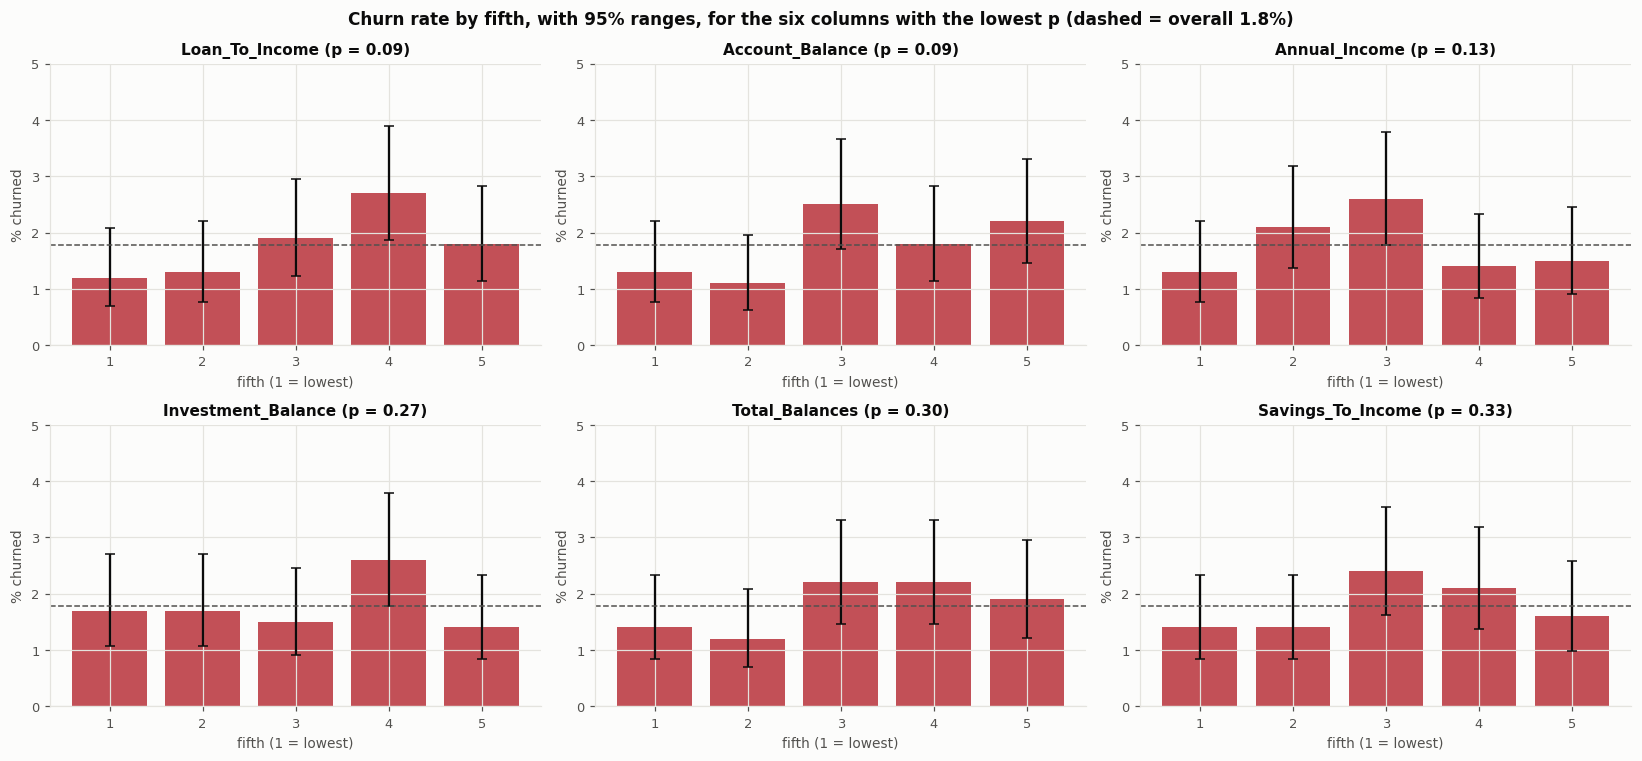

In [5]:
# Chart: churn rate by fifth, with 95% ranges, for the six columns with the lowest p.
fig, axes = plt.subplots(2, 3, figsize=(15, 7))
for ax, col in zip(axes.ravel(), evidence.Column.head(6)):
    g = pd.qcut(cust[col], 5, duplicates="drop") if cust[col].nunique() > 8 else cust[col]
    t = cust.groupby(g, observed=True).Churn_Flag.agg(["sum", "size"])
    rate = t["sum"] / t["size"]
    rng_ = np.array([proportion_confint(k, n, method="wilson") for k, n in zip(t["sum"], t["size"])])
    x = np.arange(len(t))
    ax.bar(x, rate * 100, color=CHURN, alpha=0.85)
    ax.errorbar(x, rate * 100, yerr=[(rate - rng_[:, 0]) * 100, (rng_[:, 1] - rate) * 100], fmt="none", ecolor=INK, capsize=3)
    ax.axhline(y.mean() * 100, color=INK_2, ls="--", lw=1)
    ax.set_xticks(x, [f"{i + 1}" for i in x]); ax.set_ylim(0, 5)
    p_ = evidence.set_index("Column").loc[col, "p"]
    ax.set_title(f"{col} (p = {p_:.2f})", fontsize=10); ax.set_xlabel("fifth (1 = lowest)"); ax.set_ylabel("% churned")
fig.suptitle("Churn rate by fifth, with 95% ranges, for the six columns with the lowest p (dashed = overall 1.8%)",
             fontsize=11, fontweight="bold")
fig.tight_layout(); save_chart(fig, "01_churn_by_column"); plt.show()

## 4. The models over 25 rounds (decisions M4-09, M4-11)

| Set-up | What it is | Settings and why |
| --- | --- | --- |
| Logistic regression | A weighted sum of inputs turned into a chance | Standardised inputs; the simplest model |
| Decision tree | A flowchart of yes/no questions | Depth 3, at least 50 customers per end box: kept small because 89 churners can't support a deep tree |
| Random forest | 200 trees on random samples, averaged | At least 20 customers per end box, for the same reason |
| LightGBM | Small trees built one after another, each fixing the last one's errors | 200 trees of 4 leaves, learning rate 0.05, at least 30 customers per leaf: deliberately light |
| LightGBM, broad search (step 7) | The same LightGBM on 115 inputs | A feature-engineering check |

**Why the settings are fixed, not tuned:** the shuffled-label test (step 5) runs each set-up 100 more times on shuffled labels. Tuning inside every run would make the test far slower. And with 89 churners, a tuned setting would mostly reflect luck.

**Measured in each round, on customers the model never saw:**
- **ROC-AUC:** the chance a random churner ranks above a random stayer (0.5 = coin flip).
- **PR-AUC:** how well churners are pushed to the top of the list. Guessing scores the churn rate, 0.018.
- **Brier score:** the average of (predicted chance − actual outcome)². Lower = more honest chances. Guessing the churn rate for everyone scores 0.0175.

In [6]:
X15 = cust[MODEL_INPUTS]

# The broad search (step 7): logs of the 10 given columns plus every pairwise ratio and product.
B = cust[GIVEN_INPUTS].astype(float) + 1               # +1 so zero values can be logged and divided
broad_parts = [X15, np.log(B).add_prefix("ln_")]
for a, b in itertools.combinations(GIVEN_INPUTS, 2):
    broad_parts.append(pd.DataFrame({f"{a} ÷ {b}": B[a] / B[b], f"{a} × {b} (ln)": np.log(B[a]) + np.log(B[b])}))
X_broad = pd.concat(broad_parts, axis=1)
print("Broad search inputs:", X_broad.shape[1])

SETUPS = {
    "Logistic regression": (X15, lambda: make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000))),
    "Decision tree": (X15, lambda: DecisionTreeClassifier(max_depth=3, min_samples_leaf=50, random_state=SEED)),
    "Random forest": (X15, lambda: RandomForestClassifier(n_estimators=200, min_samples_leaf=20, random_state=SEED, n_jobs=4)),
    "LightGBM": (X15, lambda: LGBMClassifier(n_estimators=200, learning_rate=0.05, num_leaves=4, min_child_samples=30,
                                             random_state=SEED, verbose=-1, n_jobs=4)),
    "LightGBM, broad search (115 inputs)": (X_broad, lambda: LGBMClassifier(n_estimators=200, learning_rate=0.05, num_leaves=4,
                                                                           min_child_samples=30, random_state=SEED,
                                                                           verbose=-1, n_jobs=4)),
}
SPLITS = list(RepeatedStratifiedKFold(n_splits=5, n_repeats=5, random_state=SEED).split(X15, y))

rows, OOF = [], {}
for name, (X, make) in SETUPS.items():
    t0 = time.time()
    oof = np.zeros(len(y))
    for r, (a, b) in enumerate(SPLITS, start=1):
        p = make().fit(X.iloc[a], y[a]).predict_proba(X.iloc[b])[:, 1]
        oof[b] += p
        rows.append({"Set-up": name, "Round": r, "ROC-AUC": roc_auc_score(y[b], p),
                     "PR-AUC": average_precision_score(y[b], p), "Brier": brier_score_loss(y[b], p), "Average chance": p.mean()})
    OOF[name] = oof / 5
    g = pd.DataFrame(rows[-len(SPLITS):])
    print(f"{name:<38} {time.time() - t0:4.0f}s | ROC-AUC {g['ROC-AUC'].mean():.3f} | PR-AUC {g['PR-AUC'].mean():.4f} | "
          f"Brier {g.Brier.mean():.4f}", flush=True)
rounds = pd.DataFrame(rows)
cv_summary = rounds.groupby("Set-up", sort=False).agg(**{"ROC-AUC": ("ROC-AUC", "mean"), "ROC-AUC lowest round": ("ROC-AUC", "min"),
                                                          "ROC-AUC highest round": ("ROC-AUC", "max"), "PR-AUC": ("PR-AUC", "mean"),
                                                          "Brier": ("Brier", "mean"), "Average chance": ("Average chance", "mean")})
print(f"Guessing: PR-AUC {y.mean():.4f}, Brier {brier_score_loss(y, np.full(len(y), y.mean())):.4f}")
cv_summary.style.format({"ROC-AUC": "{:.3f}", "ROC-AUC lowest round": "{:.3f}", "ROC-AUC highest round": "{:.3f}",
                         "PR-AUC": "{:.4f}", "Brier": "{:.4f}", "Average chance": "{:.2%}"})

Broad search inputs: 115


Logistic regression                       0s | ROC-AUC 0.490 | PR-AUC 0.0235 | Brier 0.0176


Decision tree                             1s | ROC-AUC 0.489 | PR-AUC 0.0191 | Brier 0.0177


Random forest                            22s | ROC-AUC 0.502 | PR-AUC 0.0304 | Brier 0.0176


LightGBM                                  2s | ROC-AUC 0.495 | PR-AUC 0.0236 | Brier 0.0177


LightGBM, broad search (115 inputs)       7s | ROC-AUC 0.561 | PR-AUC 0.0265 | Brier 0.0177


Guessing: PR-AUC 0.0178, Brier 0.0175


,ROC-AUC,ROC-AUC lowest round,ROC-AUC highest round,PR-AUC,Brier,Average chance
Set-up,,,,,,
Logistic regression,0.490,0.348,0.596,0.0235,0.0176,1.78%
Decision tree,0.489,0.410,0.647,0.0191,0.0177,1.78%
Random forest,0.502,0.372,0.640,0.0304,0.0176,1.83%
LightGBM,0.495,0.369,0.607,0.0236,0.0177,1.70%
"LightGBM, broad search (115 inputs)",0.561,0.446,0.672,0.0265,0.0177,1.56%


## 5. The shuffled-label test (decisions M4-08, M4-11)

**The idea:** shuffle the churn flags, so they no longer belong to the right customers, and run the same model. Whatever it scores is what luck alone produces. Doing this many times gives the range of "luck" scores. A real model must score above that range.

```text
For each set-up:
  real score    = ROC-AUC with the true labels (on one 5-fold split)
  luck scores   = ROC-AUC with shuffled labels, 100 times (each on the same kind of 5-fold split)
  p             = (number of luck scores ≥ real score + 1) ÷ (100 + 1)      the chance luck does as well
```

The real score here uses one 5-fold split, the same design as each shuffled run, so like is compared with like. The 25-round average in step 4 is the steadier estimate of the real score.

**How the numbers are derived:**
- **Pass line p < 0.01:** five set-ups are tested, so the usual 0.05 is divided by 5 (Bonferroni): **0.05 ÷ 5 = 0.01**.
- **100 shuffles:** the smallest p this test can give is 1 ÷ (shuffles + 1). With 100 shuffles that is 1 ÷ 101 = **0.0099**, just below the 0.01 line, so a genuinely useful model *could* pass. With 50 shuffles the smallest possible p would be 1 ÷ 51 = 0.0196, and nothing could ever pass.

In [7]:
P_LINE_MODELS = 0.05 / len(SETUPS)
rng = np.random.default_rng(SEED)
ONE_SPLIT = list(StratifiedKFold(5, shuffle=True, random_state=SEED).split(X15, y))


def one_split_roc(X, make, labels):
    """Average ROC-AUC over one 5-fold split, for a given set of labels."""
    return np.mean([roc_auc_score(labels[b], make().fit(X.iloc[a], labels[a]).predict_proba(X.iloc[b])[:, 1])
                    for a, b in ONE_SPLIT])


shuffle_rows, NULLS = [], {}
for name, (X, make) in SETUPS.items():
    t0 = time.time()
    real = one_split_roc(X, make, y)
    null = np.array([one_split_roc(X, make, rng.permutation(y)) for _ in range(N_SHUFFLES)])
    NULLS[name] = null
    p = (np.sum(null >= real) + 1) / (N_SHUFFLES + 1)
    shuffle_rows.append({"Set-up": name, "Real ROC-AUC (one 5-fold split)": real, "Shuffled: average": null.mean(),
                         "Shuffled: 95th percentile": np.percentile(null, 95), "Shuffled: highest": null.max(),
                         "p (luck does as well)": p, "Passes (p < 0.01)": bool(p < P_LINE_MODELS)})
    print(f"{name:<38} {time.time() - t0:4.0f}s | real {real:.3f} | shuffled mean {null.mean():.3f}, 95th {np.percentile(null, 95):.3f} | p {p:.3f}",
          flush=True)
shuffle_tbl = pd.DataFrame(shuffle_rows)
print(f"Pass line: 0.05 ÷ {len(SETUPS)} set-ups = {P_LINE_MODELS:.3f};  smallest possible p with {N_SHUFFLES} shuffles = {1 / (N_SHUFFLES + 1):.4f}")
shuffle_tbl.style.format({c: "{:.3f}" for c in shuffle_tbl.columns if c not in ("Set-up", "Passes (p < 0.01)")}).hide(axis="index")

Logistic regression                      10s | real 0.457 | shuffled mean 0.504, 95th 0.585 | p 0.832


Decision tree                            14s | real 0.467 | shuffled mean 0.499, 95th 0.560 | p 0.842


Random forest                           483s | real 0.510 | shuffled mean 0.504, 95th 0.565 | p 0.455


LightGBM                                 36s | real 0.474 | shuffled mean 0.498, 95th 0.568 | p 0.733


LightGBM, broad search (115 inputs)     146s | real 0.534 | shuffled mean 0.504, 95th 0.562 | p 0.198


Pass line: 0.05 ÷ 5 set-ups = 0.010;  smallest possible p with 100 shuffles = 0.0099


Set-up,Real ROC-AUC (one 5-fold split),Shuffled: average,Shuffled: 95th percentile,Shuffled: highest,p (luck does as well),Passes (p < 0.01)
Logistic regression,0.457,0.504,0.585,0.626,0.832,False
Decision tree,0.467,0.499,0.560,0.602,0.842,False
Random forest,0.510,0.504,0.565,0.583,0.455,False
LightGBM,0.474,0.498,0.568,0.622,0.733,False
"LightGBM, broad search (115 inputs)",0.534,0.504,0.562,0.628,0.198,False


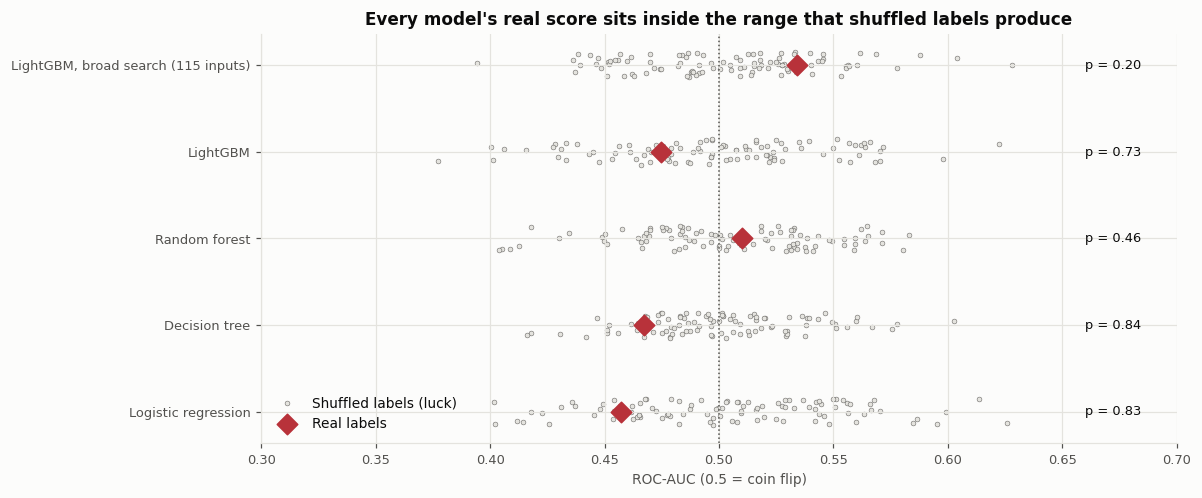

In [8]:
# Chart: each set-up's real score against its 100 shuffled-label scores.
fig, ax = plt.subplots(figsize=(11, 4.6))
for i, (name, null) in enumerate(NULLS.items()):
    ax.scatter(null, np.full(len(null), i) + np.random.default_rng(i).uniform(-0.15, 0.15, len(null)), s=10, color=GRID,
               edgecolor=INK_2, lw=0.3, label="Shuffled labels (luck)" if i == 0 else None)
    real = shuffle_tbl.loc[i, "Real ROC-AUC (one 5-fold split)"]
    ax.scatter([real], [i], s=90, color=CHURN, marker="D", label="Real labels" if i == 0 else None, zorder=3)
    ax.text(ax.get_xlim()[1] if False else 0.66, i, f"p = {shuffle_tbl.loc[i, 'p (luck does as well)']:.2f}", va="center", fontsize=8.5)
ax.axvline(0.5, color=INK_2, ls=":", lw=1)
ax.set_yticks(range(len(NULLS)), list(NULLS)); ax.set_xlim(0.30, 0.70)
ax.set_xlabel("ROC-AUC (0.5 = coin flip)"); ax.legend(frameon=False, loc="lower left")
ax.set_title("Every model's real score sits inside the range that shuffled labels produce")
fig.tight_layout(); save_chart(fig, "02_shuffled_label_test"); plt.show()

## 6. The business check: churners in the top 1,000 (decision M4-11)

The brief's executive question: *"If NovaFin can contact only 1,000 customers, which customers should it target?"* A useful churn model should put more churners in its top 1,000 than random picking would.

**How the 20% is derived:** picking 1,000 of 5,000 customers at random reaches, on average, 1,000 ÷ 5,000 = **20%** of the churners (about 18 of 89).

**Test:** a one-sided binomial test of the model's catch against 20%. Pass line: p < 0.05. The out-of-fold scores (each customer scored by models that never saw them) are used.

In [9]:
biz = []
for name, oof in OOF.items():
    top = np.argsort(-oof, kind="stable")[:CONTACTS]
    k = int(y[top].sum())
    biz.append({"Set-up": name, "Churners in top 1,000": k, "Share of the 89 churners": k / y.sum(),
                "Random picking (20%)": CONTACTS / len(y) * y.sum(),
                "p (better than random?)": stats.binomtest(k, int(y.sum()), CONTACTS / len(y), alternative="greater").pvalue})
biz = pd.DataFrame(biz)
biz["Passes (p < 0.05)"] = biz["p (better than random?)"] < 0.05
print(f"Random picking reaches {CONTACTS} ÷ {len(y):,} = {CONTACTS / len(y):.0%} of churners = {CONTACTS / len(y) * y.sum():.1f} of {y.sum()}")
biz.style.format({"Share of the 89 churners": "{:.1%}", "Random picking (20%)": "{:.1f}", "p (better than random?)": "{:.3f}"}).hide(axis="index")

Random picking reaches 1000 ÷ 5,000 = 20% of churners = 17.8 of 89


Set-up,"Churners in top 1,000",Share of the 89 churners,Random picking (20%),p (better than random?),Passes (p < 0.05)
Logistic regression,15,16.9%,17.8,0.807,False
Decision tree,18,20.2%,17.8,0.521,False
Random forest,19,21.3%,17.8,0.416,False
LightGBM,22,24.7%,17.8,0.163,False
"LightGBM, broad search (115 inputs)",21,23.6%,17.8,0.233,False


## 6b. Simple rules the bank could use today (decision M4-13)

There is no existing bank churn score in this dataset: none of the 13 columns is a churn rating. A bank without a model would call customers by a **simple rule**, such as "most complaints first". Each rule is judged exactly like the models in step 6: churners reached in the top 1,000, against random picking (20% = 1,000 ÷ 5,000), with a one-sided binomial test (p < 0.05). ROC-AUC is shown too.

Ties (for example, many customers with the same number of complaints) are broken by a fixed random order, so no rule gets an accidental advantage.

In [10]:
tie_break = np.random.default_rng(SEED).random(len(cust)) * 1e-9      # breaks ties without changing any real order
RULES = {"Most complaints first": cust.Complaints, "Lowest digital usage first": -cust.Digital_Usage,
         "Shortest relationship first": -cust.Relationship_Length_Years, "Fewest products first": -cust.Products_Held,
         "Fewest transactions first": -cust.Transactions_Per_Month, "Highest CLV first": cust.Estimated_CLV,
         "Highest total balances first": cust.Total_Balances}
rule_rows = []
for name, score in RULES.items():
    s = score.to_numpy(float) + tie_break
    top = np.argsort(-s)[:CONTACTS]
    k = int(y[top].sum())
    rule_rows.append({"Rule: call the 1,000 customers with…": name, "Churners reached": k, "Share of the 89": k / y.sum(),
                      "p (better than random?)": stats.binomtest(k, int(y.sum()), CONTACTS / len(y), alternative="greater").pvalue,
                      "ROC-AUC": roc_auc_score(y, s)})
rules_tbl = pd.DataFrame(rule_rows)
rules_tbl["Passes (p < 0.05)"] = rules_tbl["p (better than random?)"] < 0.05
print(f"Random picking reaches {CONTACTS / len(y) * y.sum():.1f} of {y.sum()} churners (20%)")
rules_tbl.style.format({"Share of the 89": "{:.1%}", "p (better than random?)": "{:.2f}", "ROC-AUC": "{:.3f}"}).hide(axis="index")

Random picking reaches 17.8 of 89 churners (20%)


"Rule: call the 1,000 customers with…",Churners reached,Share of the 89,p (better than random?),ROC-AUC,Passes (p < 0.05)
Most complaints first,20,22.5%,0.32,0.512,False
Lowest digital usage first,22,24.7%,0.16,0.546,False
Shortest relationship first,22,24.7%,0.16,0.506,False
Fewest products first,18,20.2%,0.52,0.502,False
Fewest transactions first,15,16.9%,0.81,0.489,False
Highest CLV first,14,15.7%,0.87,0.501,False
Highest total balances first,19,21.3%,0.42,0.547,False


## 7. Feature-engineering check: a broad search of 115 inputs

The 5 business-based features found nothing. To make sure we haven't missed a pattern hiding in combinations of columns, a **broad, data-driven search** builds 115 inputs: the logs of the 10 given columns, and every pairwise ratio and product (45 pairs × 2 = 90), plus the 15 model inputs. The same LightGBM is run on them (it is the fifth set-up in steps 4–6).

**Why it isn't the main model even if it scores higher:** with 115 inputs and 89 churners, a flexible model can find patterns that are pure noise. The shuffled-label test (step 5) is the judge. Its "drivers" are listed below, to check whether they make any business sense.

In [11]:
broad = LGBMClassifier(n_estimators=200, learning_rate=0.05, num_leaves=4, min_child_samples=30, random_state=SEED,
                       verbose=-1, n_jobs=4).fit(X_broad, y)
gain = pd.Series(broad.booster_.feature_importance("gain"), index=X_broad.columns).sort_values(ascending=False)
print("The broad search's top 8 inputs by importance (gain):")
print((gain.head(8) / gain.sum()).round(3).to_string())

The broad search's top 8 inputs by importance (gain):
Account_Balance × Loan_Balance (ln)              0.050
Annual_Income                                    0.036
Products_Held ÷ Complaints                       0.035
Loan_Balance × Relationship_Length_Years (ln)    0.034
Transactions_Per_Month × Loan_Balance (ln)       0.033
Products_Held × Digital_Usage (ln)               0.030
Products_Held ÷ Digital_Usage                    0.028
Digital_Usage × Investment_Balance (ln)          0.025


## 8. Why the data is not rebalanced (decision M4-11)

With 1.8% churners, a common step is to **rebalance**: make churners count more (class weights), create artificial churners (SMOTE), or drop stayers (undersampling). Each is tested here, over the same 25 rounds.

**What to look for:** rebalancing can't create information that isn't there. It changes the *scale* of the chances. If the ranking (ROC-AUC) doesn't improve while the average chance jumps above the real 1.8%, rebalancing only distorts what Task 3 needs: value at risk = chance of churn × CLV.

In [12]:
def balance_run(make, how):
    """25-round scores for one model with one rebalancing method."""
    out = []
    for a, b in SPLITS:
        Xa, ya = X15.iloc[a].to_numpy(), y[a]
        if how == "SMOTE (artificial churners)":
            Xa, ya = SMOTE(random_state=SEED).fit_resample(Xa, ya)
        elif how == "Undersample stayers to 1:5":
            r = np.random.default_rng(SEED)
            pos = np.where(ya == 1)[0]
            neg = r.choice(np.where(ya == 0)[0], len(pos) * 5, replace=False)
            keep = np.concatenate([pos, neg]); Xa, ya = Xa[keep], ya[keep]
        p = make(how == "Class weights").fit(Xa, ya).predict_proba(X15.iloc[b].to_numpy())[:, 1]
        out.append((roc_auc_score(y[b], p), brier_score_loss(y[b], p), p.mean()))
    return np.mean(out, axis=0)


makers = {"Logistic regression": lambda w: make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000, class_weight="balanced" if w else None)),
          "LightGBM": lambda w: LGBMClassifier(n_estimators=200, learning_rate=0.05, num_leaves=4, min_child_samples=30,
                                               class_weight="balanced" if w else None, random_state=SEED, verbose=-1, n_jobs=4)}
bal = []
for model, make in makers.items():
    for how in ["None", "Class weights", "SMOTE (artificial churners)", "Undersample stayers to 1:5"]:
        roc, br, avg = balance_run(make, how)
        bal.append({"Model": model, "Rebalancing": how, "ROC-AUC": roc, "Average predicted chance": avg, "Brier": br})
bal = pd.DataFrame(bal)
print(f"Actual churn rate: {y.mean():.2%};  Brier when guessing the churn rate for everyone: {brier_score_loss(y, np.full(len(y), y.mean())):.4f}")
bal.style.format({"ROC-AUC": "{:.3f}", "Average predicted chance": "{:.1%}", "Brier": "{:.4f}"}).hide(axis="index")

Actual churn rate: 1.78%;  Brier when guessing the churn rate for everyone: 0.0175


Model,Rebalancing,ROC-AUC,Average predicted chance,Brier
Logistic regression,None,0.490,1.8%,0.0176
Logistic regression,Class weights,0.489,47.7%,0.2405
Logistic regression,SMOTE (artificial churners),0.485,47.2%,0.2408
Logistic regression,Undersample stayers to 1:5,0.500,16.6%,0.0441
LightGBM,None,0.495,1.7%,0.0177
LightGBM,Class weights,0.498,31.2%,0.1363
LightGBM,SMOTE (artificial churners),0.477,17.8%,0.0523
LightGBM,Undersample stayers to 1:5,0.508,15.7%,0.0502


## 9. What the model says drives churn

A logistic regression on the 10 given columns, fitted on all 5,000 customers, with each weight's 95% range. The 5 derived features are left out here because some are exact sums of given columns, which a weight table can't separate.

```text
Odds ratio = e^weight, per 1 standard deviation of the input:  1.00 = no effect; above 1 = more churn; below 1 = less
```

A driver is significant only if its p is below 0.05 ÷ 10 = 0.005 (Bonferroni over 10 weights).

In [13]:
Z = (cust[GIVEN_INPUTS] - cust[GIVEN_INPUTS].mean()) / cust[GIVEN_INPUTS].std()
logit = sm.Logit(y, sm.add_constant(Z)).fit(disp=0)
ci = logit.conf_int()
drivers = pd.DataFrame({"Odds ratio per 1 std": np.exp(logit.params), "95% low": np.exp(ci[0]), "95% high": np.exp(ci[1]),
                        "p": logit.pvalues}).drop(index="const").sort_values("p")
drivers["Significant (p < 0.005)"] = drivers.p < 0.05 / len(GIVEN_INPUTS)
print(f"Significant drivers: {drivers['Significant (p < 0.005)'].sum()} of {len(drivers)};  "
      f"whole-model test (all weights zero?): p = {logit.llr_pvalue:.2f}")
drivers.style.format({"Odds ratio per 1 std": "{:.2f}", "95% low": "{:.2f}", "95% high": "{:.2f}", "p": "{:.3f}"})

Significant drivers: 0 of 10;  whole-model test (all weights zero?): p = 0.63


,Odds ratio per 1 std,95% low,95% high,p,Significant (p < 0.005)
Investment_Balance,0.77,0.57,1.05,0.095,False
Digital_Usage,0.85,0.69,1.04,0.111,False
Account_Balance,1.29,0.93,1.79,0.134,False
Annual_Income,0.91,0.72,1.15,0.416,False
Complaints,1.08,0.88,1.33,0.433,False
Products_Held,0.96,0.78,1.18,0.684,False
Age,0.97,0.78,1.19,0.740,False
Relationship_Length_Years,0.97,0.79,1.20,0.768,False
Loan_Balance,0.97,0.71,1.33,0.853,False
Transactions_Per_Month,1.00,0.81,1.24,0.980,False


## 10. What the results say

### The answer: churn cannot be predicted from this data

Every test agreed on before the results was run, and every one fails:

| Test (pass line, and how it is derived) | Result |
| --- | --- |
| Any single column separates churners (p < 0.05 ÷ 15 = 0.0033) | **0 of 15.** The lowest p is 0.086 (loan ÷ income) |
| Any model beats shuffled labels (p < 0.05 ÷ 5 = 0.01; 100 shuffles) | **0 of 5.** p = 0.20 to 0.84 |
| Any model puts more churners in its top 1,000 than random picking (20% = 1,000 ÷ 5,000; p < 0.05) | **0 of 5.** 15 to 22 churners, against 17.8 by random picking; p = 0.16 to 0.81 |
| Any simple bank rule does (same test) | **0 of 7.** 14 to 22 churners; p = 0.16 to 0.87 |
| Any driver of churn is significant (p < 0.05 ÷ 10 = 0.005) | **0 of 10.** The whole model is no better than no model (p = 0.63) |

### The models (steps 4–6)

| Set-up | ROC-AUC over 25 rounds (lowest – highest round) | Real vs shuffled labels: p | Churners in top 1,000 (of 89) | Average predicted chance |
| --- | --- | --- | --- | --- |
| Logistic regression | 0.490 (0.35–0.60) | 0.83 | 15 (16.9%) | 1.78% |
| Decision tree | 0.489 (0.41–0.65) | 0.84 | 18 (20.2%) | 1.78% |
| Random forest | 0.502 (0.37–0.64) | 0.46 | 19 (21.3%) | 1.83% |
| LightGBM | 0.495 (0.37–0.61) | 0.73 | 22 (24.7%) | 1.70% |
| LightGBM, broad search (115 inputs) | 0.561 (0.45–0.67) | 0.20 | 21 (23.6%) | 1.56% |
| *Random picking* | *0.500* | — | *17.8 (20%)* | — |

- **Every model scores what shuffled labels score.** The real-label scores sit inside the range of 100 luck runs each (smallest p = 0.20; chart above).
- **The wide spread between rounds** (for example 0.35 to 0.60 for logistic regression) comes from about 18 churners per test part. One churner ranked differently moves the score a lot. This is why 25 rounds and the shuffled-label test are needed: a single split could have shown 0.65 by luck.
- **The broad search scores highest (0.561 over 25 rounds; 0.534 on the one split used for the luck test, where shuffled labels reach 0.562 at their 95th percentile).** Its "drivers" have no business story: account balance × loan balance, products ÷ complaints. It found patterns in noise.

### Simple rules the bank could use today (step 6b)

There's no existing bank churn score in this file, so the comparison is with rules a bank would use without a model:

| Rule: call the 1,000 customers with… | Churners reached (of 89) | Better than random? (p) | ROC-AUC |
| --- | --- | --- | --- |
| Most complaints | 20 (22.5%) | No (0.32) | 0.512 |
| Lowest digital usage | 22 (24.7%) | No (0.16) | 0.546 |
| Shortest relationship | 22 (24.7%) | No (0.16) | 0.506 |
| Fewest products | 18 (20.2%) | No (0.52) | 0.502 |
| Fewest transactions | 15 (16.9%) | No (0.81) | 0.489 |
| Highest CLV | 14 (15.7%) | No (0.87) | 0.501 |
| Highest total balances | 19 (21.3%) | No (0.42) | 0.547 |
| *Random picking* | *17.8 (20%)* | — | *0.500* |

**No rule of thumb does better than the models, and none beats calling at random beyond chance.** Neither a rule a bank would use today nor a model can single out who will leave.

### Rebalancing makes things worse (step 8)

| Model | Rebalancing | ROC-AUC | Average predicted chance (actual 1.78%) | Brier (guessing: 0.0175) |
| --- | --- | --- | --- | --- |
| Logistic regression | None | 0.490 | **1.8%** | **0.0176** |
| | Class weights | 0.489 | 47.7% | 0.2405 |
| | SMOTE | 0.485 | 47.2% | 0.2408 |
| | Undersample 1:5 | 0.500 | 16.6% | 0.0441 |
| LightGBM | None | 0.495 | **1.7%** | **0.0177** |
| | Class weights | 0.498 | 31.2% | 0.1363 |
| | SMOTE | 0.477 | 17.8% | 0.0523 |
| | Undersample 1:5 | 0.508 | 15.7% | 0.0502 |

- **Rebalancing doesn't improve the ranking,** because it can't create information that isn't there.
- **It inflates every chance 9 to 27 times,** which would wreck Task 3's value at risk (chance of churn × CLV).

### What this means for the business
- **₹55.96 lakh of lifetime value walked out with the 89 churners**: 1.7% of the ₹32.80 crore total. That is roughly the same share as the churn rate itself (churners are worth about the same as stayers: median CLV ₹55,579 vs ₹54,195).
- **No column in this file tells the bank who is about to leave.** Calling the "most at-risk" 1,000 by any model reaches 15–22 of the 89 churners, no more than calling 1,000 at random (about 18) beyond chance.
- **So for the executive question, churn risk can't do the targeting.** Task 3 will have to decide how to build the "High / Low Churn" groups and the 1,000-customer list when churn risk is the same for everyone. CLV (Task 2) becomes the main lever.
- **What would help:** data that moves before a customer leaves, such as falling balances or transactions month by month, closed products, competitor offers, or service contacts. This file holds one snapshot per customer.

### What goes to Task 3 (decision M4-10)
- `outputs/task1/FINAL_M4_T1_churn_scores.csv`: each customer's out-of-fold chance of churn from the **logistic regression**, labelled **"Churn predictable: No: scores no better than chance"**.
  - **Why logistic regression:** when nothing beats luck, there is no basis to prefer a complex model.
  - **Its chances are on an honest scale:** average 1.78%, the real rate.
  - Middle 80% of customers: 1.1% to 2.4%. That spread is noise.
- `model_tests.csv` and `evidence_table.csv`: the evidence.

## 11. Save the outputs (decision M4-10)

**Which scores go to Task 3.** If a set-up passed both the shuffled-label test and the business check, its out-of-fold scores would go on. **If none passes, the simplest model's (logistic regression) out-of-fold scores go on**, labelled no better than chance. When nothing beats luck, there is no basis to prefer a complex model, and the logistic model's chances average the real churn rate (honest scale).

- **`FINAL_M4_T1_churn_scores.csv`:** Customer_ID, Churn_Flag, P_churn (out-of-fold), and whether churn was found predictable.
- **`evidence_table.csv`:** each column's test. **`model_tests.csv`:** each set-up's 25-round scores, shuffled-label test and business check. The simple rules (step 6b) are shown above and in the report.
- `churn_model.joblib`: the handed-on model refitted on all 5,000 customers. The charts above and `key_numbers.json`.

In [14]:
tests = cv_summary.reset_index().merge(shuffle_tbl, on="Set-up").merge(biz, on="Set-up")
tests["Useful (passes both)"] = tests["Passes (p < 0.01)"] & tests["Passes (p < 0.05)"]
save_table(tests.round(4), "model_tests")
passing = tests[tests["Useful (passes both)"]]
PREDICTABLE = len(passing) > 0
HANDED = passing.sort_values("ROC-AUC", ascending=False)["Set-up"].iloc[0] if PREDICTABLE else "Logistic regression"
print(f"Churn predictable from this data: {PREDICTABLE};  scores handed to Task 3: {HANDED}")

scores = pd.DataFrame({"Customer_ID": cust.Customer_ID, "Churn_Flag": y, "P_churn": OOF[HANDED].round(6),
                       "Model": HANDED, "Churn predictable": "Yes" if PREDICTABLE else "No: scores no better than chance"})
save_table(scores, "FINAL_M4_T1_churn_scores")
X_h, make_h = SETUPS[HANDED]
joblib.dump(make_h().fit(X_h, y), OUT_DIR / "churn_model.joblib")


def r4(v):
    return round(float(v), 4)


key = {"churners": int(y.sum()), "churn_rate": r4(y.mean()), "predictable": PREDICTABLE, "handed": HANDED,
       "p_line_columns": r4(P_LINE_COLUMNS), "p_line_models": r4(P_LINE_MODELS), "columns_significant": int(evidence["Separates churners"].sum()),
       "lowest_column_p": r4(evidence.p.min()),
       "setups": {r["Set-up"]: {"roc_auc": r4(r["ROC-AUC"]), "shuffle_p": r4(r["p (luck does as well)"]),
                                "top1000": int(r["Churners in top 1,000"]), "top1000_p": r4(r["p (better than random?)"])} for _, r in tests.iterrows()},
       "handed_average_chance": r4(OOF[HANDED].mean()),
       "rules": {r["Rule: call the 1,000 customers with…"]: {"churners": int(r["Churners reached"]), "p": r4(r["p (better than random?)"])}
                 for _, r in rules_tbl.iterrows()}}
(OUT_DIR / "key_numbers.json").write_text(json.dumps(key, indent=1, ensure_ascii=False), encoding="utf-8")
print("Saved to", OUT_DIR.relative_to(PROJECT_ROOT).as_posix())
print(sorted(p.name for p in OUT_DIR.iterdir()))

Churn predictable from this data: False;  scores handed to Task 3: Logistic regression


Saved to module_04_customer_analytics/outputs/task1
['01_churn_by_column.png', '02_shuffled_label_test.png', 'FINAL_M4_T1_churn_scores.csv', 'churn_model.joblib', 'evidence_table.csv', 'key_numbers.json', 'model_tests.csv']
